# 02 · Modelling: 9 classifiers, walk-forward validation 2005–2020

This notebook is the brief's documented modelling deliverable:

1. **Pipeline:** the modelling table (14 features + label) and the walk-forward folds
2. **Models:** the 9 scikit-learn / XGBoost classifiers, their preparation and search spaces
3. **Training and tuning:** for each year 2005–2020, tune on 5 inner folds by macro-F1, retrain, predict that year
4. **Comparison:** macro-F1, balanced accuracy and accuracy, overall and per year, with confidence intervals
5. **Tuned settings:** which settings won in each year
6. **Shortlist:** the top 3 by macro-F1 go on to the money test in notebook 03
7. **Interpretation:** confusion matrices, coefficients and permutation importance

The test years 2021 → latest are **not used here**. They are opened once, in notebook 03, after the model is chosen.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.inspection import permutation_importance

from src.data import load_spy
from src.features import build_features, FEATURES, FEATURE_INFO
from src.labels import make_labels, CLASS_NAMES, CLASS_ORDER
from src.splits import walk_forward_folds, inner_splits
from src.models import (MODEL_NAMES, MODEL_SPECS, run_walk_forward, always_buy_proba, classification_scores,
                        block_bootstrap_ci, macro_f1, search_space_text, make_search)
from src import plotting as P

P.setup()
import os
QUICK = os.environ.get("SPY_QUICK") == "1"  # developer smoke test: only the last 2 validation years
RES = ROOT / ("results_quick" if QUICK else "results"); RES.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)

## 1. Modelling table and walk-forward folds

In [2]:
px = load_spy()
feats = build_features(px)
y_all = make_labels(px["close"])
data = feats.join(y_all).dropna()
X, y = data[FEATURES], data["label"].astype(int)
print(f"{len(X):,} rows × {X.shape[1]} features, {X.index[0].date()} to {X.index[-1].date()}")

folds = walk_forward_folds(X.index)
fold_table = pd.DataFrame([f.describe(X.index) for f in folds]).set_index("fold")
fold_table

8,283 rows × 14 features, 1993-11-11 to 2026-10-09


,phase,predict year,train from,train to,train rows,predict from,predict to,predict rows
fold,,,,,,,,
1,validate,2005,1993-11-11,2004-12-23,2801,2005-01-03,2005-12-30,252
2,validate,2006,1993-11-11,2005-12-22,3053,2006-01-03,2006-12-29,251
3,validate,2007,1993-11-11,2006-12-21,3304,2007-01-03,2007-12-31,251
4,validate,2008,1993-11-11,2007-12-21,3555,2008-01-02,2008-12-31,253
5,validate,2009,1993-11-11,2008-12-23,3808,2009-01-02,2009-12-31,252
6,validate,2010,1993-11-11,2009-12-23,4060,2010-01-04,2010-12-31,252
7,validate,2011,1993-11-11,2010-12-23,4312,2011-01-03,2011-12-30,252
8,validate,2012,1993-11-11,2011-12-22,4564,2012-01-03,2012-12-31,250
9,validate,2013,1993-11-11,2012-12-21,4814,2013-01-02,2013-12-31,252


Each fold trains on every year before the predicted year, minus the last **5 rows** (their 5-day labels reach into the predicted year). Inside each training window, the 5 most recent ~1-year blocks act as practice exams for tuning. Example for fold 1:

In [3]:
f1_ = folds[0]
d_tr = X.index[f1_.train_idx]
rows = []
for k, (tr, va) in enumerate(inner_splits(len(f1_.train_idx)), 1):
    rows.append({"inner fold": k, "inner train": f"{d_tr[tr[0]].date()} to {d_tr[tr[-1]].date()}",
                 "gap rows": va[0] - tr[-1] - 1, "inner validate": f"{d_tr[va[0]].date()} to {d_tr[va[-1]].date()}"})
pd.DataFrame(rows).set_index("inner fold")

,inner train,gap rows,inner validate
inner fold,,,
1,1993-11-11 to 1999-12-10,5,1999-12-20 to 2000-12-15
2,1993-11-11 to 2000-12-08,5,2000-12-18 to 2001-12-21
3,1993-11-11 to 2001-12-14,5,2001-12-24 to 2002-12-23
4,1993-11-11 to 2002-12-16,5,2002-12-24 to 2003-12-23
5,1993-11-11 to 2003-12-16,5,2003-12-24 to 2004-12-23


## 2. The models

All 9 table-based classification models from Module 3. The text and image models (DistilBERT, CNN, ResNet18) don't apply to price data. Every model is a Pipeline, so scaling and oversampling are fitted on training rows only.

In [4]:
spec_table = pd.DataFrame([search_space_text(m) for m in MODEL_NAMES]).set_index("model")
spec_table

,scaling,class imbalance,settings searched,candidates per fold
model,,,,
Dummy,No,n/a,"strategy: most_frequent, stratified",2
K-nearest neighbours,Yes,oversample training folds,"n_neighbors: 5 to 200; weights: uniform, distance",20
Logistic regression,Yes,class_weight,"C: 0.001 to 10 (log scale); l1_ratio: 0.0, 1.0",20
Decision tree,No,class_weight,max_depth: 2 to 8; min_samples_leaf: 20 to 200,20
Random forest,No,class_weight,"n_estimators: 100, 200, 300; max_depth: 3 to 10; min_samples_leaf: 20 to 200; max_features: sqrt, 0.5",12
HistGradientBoosting,No,class_weight,learning_rate: 0.01 to 0.2 (log scale); max_iter: 100 to 500; max_leaf_nodes: 8 to 31; l2_regularization: 0 to 1,12
XGBoost,No,balanced sample weights,n_estimators: 100 to 500; learning_rate: 0.01 to 0.2 (log scale); max_depth: 2 to 6; subsample: 0.6 to 1; colsample_...,12
Perceptron,Yes,class_weight,"alpha: 1e-05 to 0.01 (log scale); penalty: l2, l1, elasticnet",20
MLP,Yes,oversample training folds,"hidden_layer_sizes: (16,), (32,), (32, 16); alpha: 0.0001 to 0.1 (log scale); learning_rate_init: 0.0001 to 0.01 (lo...",12


## 3. Train, tune and predict 2005–2020

For each model and each year: draw candidate settings, score each by **macro-F1** on the 5 inner folds, keep the best mean, retrain on all training years, then predict the year. Results are cached in `results/`, so re-running the notebook is fast. Delete `results/val_*` to recompute; the first run takes roughly an hour on a laptop.

In [5]:
val_folds = [f for f in folds if f.phase == "validate"]
if QUICK:
    val_folds = val_folds[-2:]
slug = lambda m: m.lower().replace(" ", "_").replace("-", "_")
val_proba, val_logs = {}, []
for m in MODEL_NAMES:
    pf, lf = RES / f"val_proba_{slug(m)}.parquet", RES / f"val_log_{slug(m)}.json"
    if pf.exists() and lf.exists():
        val_proba[m] = pd.read_parquet(pf)
        val_logs.append(pd.read_json(lf))
        print(f"loaded {m}")
        continue
    print(f"running {m} ...")
    p, log = run_walk_forward(m, X, y, val_folds, verbose=True)
    p.to_parquet(pf); log.to_json(lf, indent=1)
    val_proba[m] = p; val_logs.append(log)
val_idx = np.concatenate([f.test_idx for f in val_folds])
val_proba["Always predict Buy"] = always_buy_proba(X.index[val_idx], X.index[val_idx].year)
val_log = pd.concat(val_logs, ignore_index=True)

loaded Dummy
loaded K-nearest neighbours
loaded Logistic regression
loaded Decision tree
loaded Random forest
loaded HistGradientBoosting
loaded XGBoost
loaded Perceptron
loaded MLP


## 4. Comparison over 2005–2020

In [6]:
y_val = y.iloc[val_idx]
order = ["Dummy", "Always predict Buy"] + [m for m in MODEL_NAMES if m != "Dummy"]
rows = []
for m in order:
    pred = val_proba[m]["pred"].reindex(y_val.index)
    s = classification_scores(y_val, pred)
    lo, hi = block_bootstrap_ci(y_val.values, pred.values, macro_f1)
    alo, ahi = block_bootstrap_ci(y_val.values, pred.values, lambda a, b: (a == b).mean())
    rows.append({"model": m, **s, "macro_f1 95% CI": f"{lo:.3f} to {hi:.3f}", "accuracy 95% CI": f"{alo:.3f} to {ahi:.3f}"})
comparison = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
comparison

,macro_f1,balanced_acc,accuracy,macro_f1 95% CI,accuracy 95% CI
model,,,,,
MLP,0.423,0.431,0.466,0.402 to 0.446,0.442 to 0.492
Random forest,0.421,0.430,0.468,0.398 to 0.444,0.442 to 0.493
Logistic regression,0.421,0.432,0.483,0.396 to 0.443,0.454 to 0.506
K-nearest neighbours,0.414,0.423,0.461,0.393 to 0.434,0.436 to 0.486
Decision tree,0.400,0.404,0.434,0.378 to 0.424,0.407 to 0.464
XGBoost,0.399,0.402,0.439,0.376 to 0.420,0.412 to 0.464
HistGradientBoosting,0.391,0.392,0.423,0.368 to 0.412,0.398 to 0.447
Perceptron,0.357,0.356,0.380,0.334 to 0.380,0.356 to 0.408
Dummy,0.340,0.341,0.354,0.327 to 0.353,0.340 to 0.367


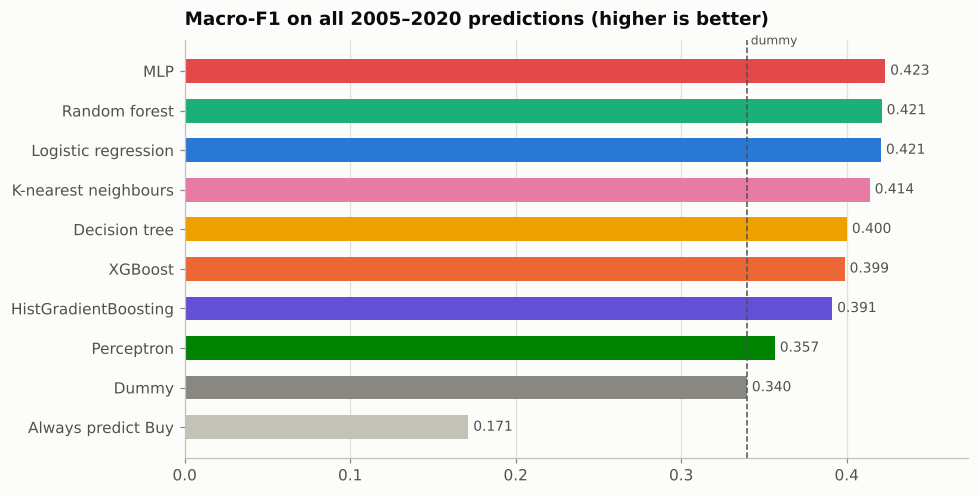

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.6))
cmp_ = comparison.sort_values("macro_f1")
cols = [P.MODEL_COLORS.get(m, P.MUTED) for m in cmp_.index]
ax.barh(cmp_.index, cmp_["macro_f1"], color=cols, height=0.6)
for i, (m, v) in enumerate(cmp_["macro_f1"].items()):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", color=P.INK2, fontsize=9)
base = comparison.loc["Dummy", "macro_f1"]
ax.axvline(base, color=P.INK2, ls="--", lw=1)
ax.text(base, len(cmp_) - 0.4, " dummy", color=P.INK2, fontsize=8, va="bottom")
ax.set_xlim(0, max(0.45, cmp_["macro_f1"].max() + 0.05)); ax.grid(axis="y", visible=False)
ax.set_title("Macro-F1 on all 2005–2020 predictions (higher is better)")
fig.tight_layout(); P.save(fig, "02_model_comparison")

### Macro-F1 per year

,mean,std,min,max
MLP,0.365,0.062,0.247,0.452
K-nearest neighbours,0.364,0.055,0.272,0.452
Random forest,0.360,0.054,0.279,0.458
Logistic regression,0.357,0.058,0.260,0.446
HistGradientBoosting,0.353,0.028,0.306,0.410
XGBoost,0.348,0.038,0.294,0.407
Decision tree,0.340,0.053,0.226,0.428
Dummy,0.331,0.024,0.284,0.359
Perceptron,0.299,0.082,0.167,0.443
Always predict Buy,0.170,0.026,0.116,0.222


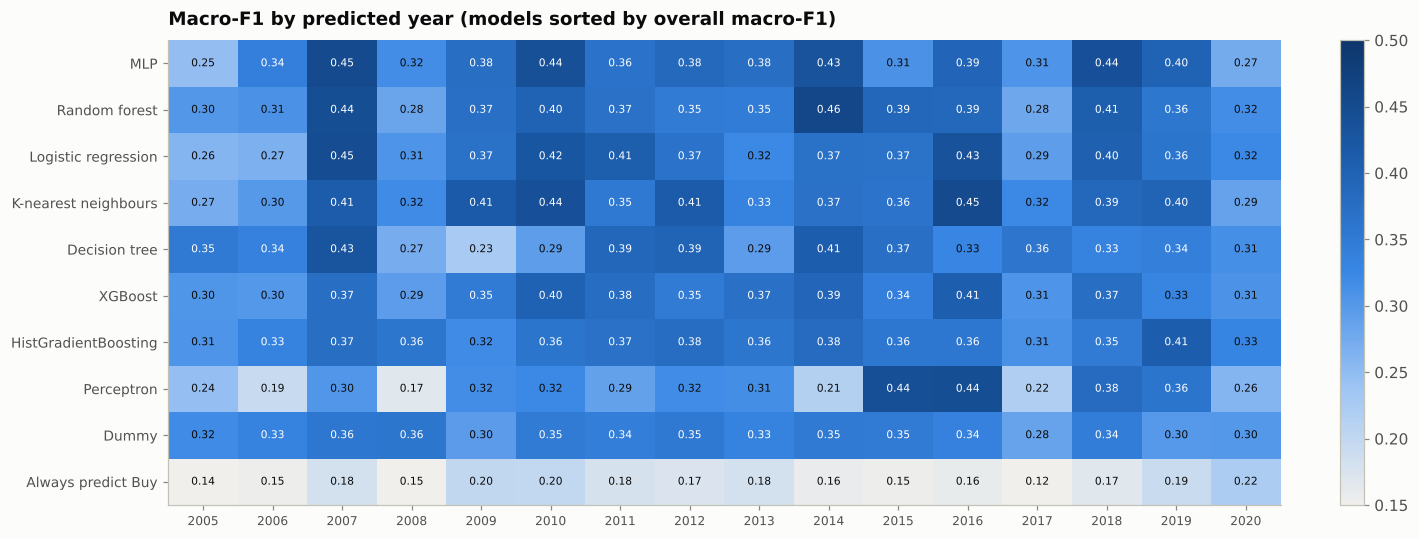

In [8]:
per_year = pd.DataFrame({m: [macro_f1(y_val[y_val.index.year == yr], val_proba[m]["pred"].reindex(y_val.index)[y_val.index.year == yr])
                             for yr in sorted(set(y_val.index.year))] for m in comparison.index},
                        index=sorted(set(y_val.index.year))).T
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(per_year.values, cmap=P.SEQUENTIAL, aspect="auto", vmin=0.15, vmax=0.5)
ax.set_xticks(range(per_year.shape[1]), per_year.columns, fontsize=8)
ax.set_yticks(range(per_year.shape[0]), per_year.index, fontsize=9)
for i in range(per_year.shape[0]):
    for j in range(per_year.shape[1]):
        v = per_year.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.33 else P.INK)
ax.grid(False); ax.set_title("Macro-F1 by predicted year (models sorted by overall macro-F1)")
fig.colorbar(im, ax=ax, fraction=0.02)
fig.tight_layout(); P.save(fig, "02_macro_f1_by_year")
per_year.T.describe().T[["mean", "std", "min", "max"]].sort_values("mean", ascending=False)

## 5. Tuned settings

The best settings are re-chosen every year. The table shows each year's winner and its inner-fold macro-F1 (mean ± SD over the 5 practice years). Settings that jump around from year to year mean the model has no stable best configuration.

In [9]:
def settings_table(m):
    t = val_log[val_log.model == m][["year", "best_params", "inner_f1_mean", "inner_f1_sd"]].copy()
    params = pd.json_normalize(t["best_params"].tolist()).set_index(t.index)
    return pd.concat([t[["year"]], params, t[["inner_f1_mean", "inner_f1_sd"]]], axis=1).set_index("year")

settings = {m: settings_table(m) for m in MODEL_NAMES}
summary_rows = []
for m, t in settings.items():
    for p in [c for c in t.columns if not c.startswith("inner_")]:
        vc = t[p].astype(str).value_counts()
        changes = int((t[p].astype(str) != t[p].astype(str).shift()).sum() - 1)
        summary_rows.append({"model": m, "setting": p, "most often best": vc.index[0], "times (of 16)": int(vc.iloc[0]),
                             "best for 2020": t[p].iloc[-1], "changed between years": changes})
settings_summary = pd.DataFrame(summary_rows).set_index(["model", "setting"])
settings_summary

most often best  times (of 16)  \
model                setting                                                    
Dummy                strategy                       stratified             16   
K-nearest neighbours n_neighbors                            93              5   
                     weights                           uniform             10   
Logistic regression  C                                0.114009              8   
                     l1_ratio                              1.0             13   
Decision tree        max_depth                               8              6   
                     min_samples_leaf                      141              4   
Random forest        max_depth                               8             11   
                     max_features                         sqrt             12   
                     min_samples_leaf                       21              8   
                     n_estimators                          200              9   
HistGradientBoosting l2_regularization                0.598658              4   
                     learning_rate                    0.015958              4   
                     max_iter                              314              4   
                     max_leaf_nodes                         18              4   
XGBoost              colsample_bytree       0.6923579999999999              4   
                     learning_rate                    0.020586              4   
                     max_depth                               5              5   
                     n_estimators                          363              4   
                     subsample              0.6137549999999999              4   
Perceptron           alpha                             2.9e-05              3   
                     penalty                                l2              7   
MLP                  alpha                            0.000138              6   
                     hidden_layer_sizes               [32, 16]             14   
                     learning_rate_init  0.0008169999999999999              6   

                                        best for 2020  changed between years  
model                setting                                                  
Dummy                strategy              stratified                      0  
K-nearest neighbours n_neighbors                   92                      8  
                     weights                  uniform                      2  
Logistic regression  C                          0.022                     11  
                     l1_ratio                   1.000                      5  
Decision tree        max_depth                      7                      9  
                     min_samples_leaf             108                     11  
Random forest        max_depth                      8                      5  
                     max_features               0.500                      2  
                     min_samples_leaf             194                      6  
                     n_estimators                 200                      5  
HistGradientBoosting l2_regularization          0.939                     10  
                     learning_rate              0.010                     10  
                     max_iter                     376                     10  
                     max_leaf_nodes                 8                     10  
XGBoost              colsample_bytree           0.944                     12  
                     learning_rate              0.077                     12  
                     max_depth                      2                     10  
                     n_estimators                 266                     12  
                     subsample                  0.605                     12  
Perceptron           alpha                      0.000                     12  
                     penalty              

In [10]:
for m in MODEL_NAMES:
    print(f"\n{m}")
    display(settings[m])


Dummy


,strategy,inner_f1_mean,inner_f1_sd
year,,,
2005,stratified,0.315,0.013
2006,stratified,0.313,0.009
2007,stratified,0.322,0.017
2008,stratified,0.314,0.027
2009,stratified,0.322,0.027
2010,stratified,0.324,0.028
2011,stratified,0.329,0.026
2012,stratified,0.332,0.024
2013,stratified,0.316,0.030



K-nearest neighbours


,n_neighbors,weights,inner_f1_mean,inner_f1_sd
year,,,,
2005,156,uniform,0.351,0.059
2006,97,uniform,0.343,0.047
2007,93,uniform,0.350,0.046
2008,93,uniform,0.346,0.037
2009,93,uniform,0.348,0.035
2010,93,uniform,0.361,0.043
2011,93,uniform,0.381,0.051
2012,79,uniform,0.391,0.052
2013,104,distance,0.395,0.056



Logistic regression


...

,colsample_bytree,learning_rate,max_depth,n_estimators,subsample,inner_f1_mean,inner_f1_sd
year,,,,,,,
2005,0.692,0.021,5,363,0.614,0.341,0.028
2006,0.964,0.022,5,101,0.770,0.337,0.020
2007,0.750,0.173,4,171,0.839,0.347,0.025
2008,0.692,0.021,5,363,0.614,0.358,0.036
2009,0.750,0.173,4,171,0.839,0.342,0.022
2010,0.657,0.070,6,357,0.889,0.345,0.016
2011,0.692,0.021,5,363,0.614,0.366,0.048
2012,0.662,0.016,4,187,0.733,0.381,0.062
2013,0.977,0.054,3,364,0.606,0.374,0.043



Perceptron


,alpha,penalty,inner_f1_mean,inner_f1_sd
year,,,,
2005,0.000,elasticnet,0.332,0.026
2006,0.000,l2,0.350,0.060
2007,0.000,l2,0.333,0.069
2008,0.000,l2,0.371,0.051
2009,0.000,elasticnet,0.333,0.038
2010,0.000,elasticnet,0.344,0.051
2011,0.000,l2,0.362,0.048
2012,0.000,elasticnet,0.371,0.058
2013,0.000,l1,0.352,0.061



MLP


,alpha,hidden_layer_sizes,learning_rate_init,inner_f1_mean,inner_f1_sd
year,,,,,
2005,0.007,[16],0.001,0.357,0.034
2006,0.023,"[32, 16]",0.001,0.340,0.033
2007,0.000,"[32, 16]",0.001,0.368,0.025
2008,0.023,"[32, 16]",0.001,0.362,0.059
2009,0.000,"[32, 16]",0.001,0.375,0.053
2010,0.000,"[32, 16]",0.001,0.367,0.054
2011,0.000,"[32, 16]",0.001,0.388,0.060
2012,0.000,"[32, 16]",0.001,0.398,0.059
2013,0.001,"[32, 16]",0.000,0.383,0.049


## 6. Shortlist

The top 3 models by macro-F1 over all 2005–2020 predictions, excluding the two baselines, go on to the money test in notebook 03. There, the final model and its Sell cut-off are picked by excess return, yearly win rate and Sharpe.

In [11]:
ranked = comparison.drop(index=["Dummy", "Always predict Buy"]).sort_values("macro_f1", ascending=False)
shortlist = list(ranked.index[:3])
print("Shortlist:", shortlist)
json.dump({"shortlist": shortlist, "macro_f1": {m: float(ranked.loc[m, "macro_f1"]) for m in shortlist}},
          open(RES / "shortlist.json", "w"), indent=1)

Shortlist: ['MLP', 'Random forest', 'Logistic regression']


## 7. Interpretation

### Confusion matrices (2005–2020, rows = true class, normalised by row)

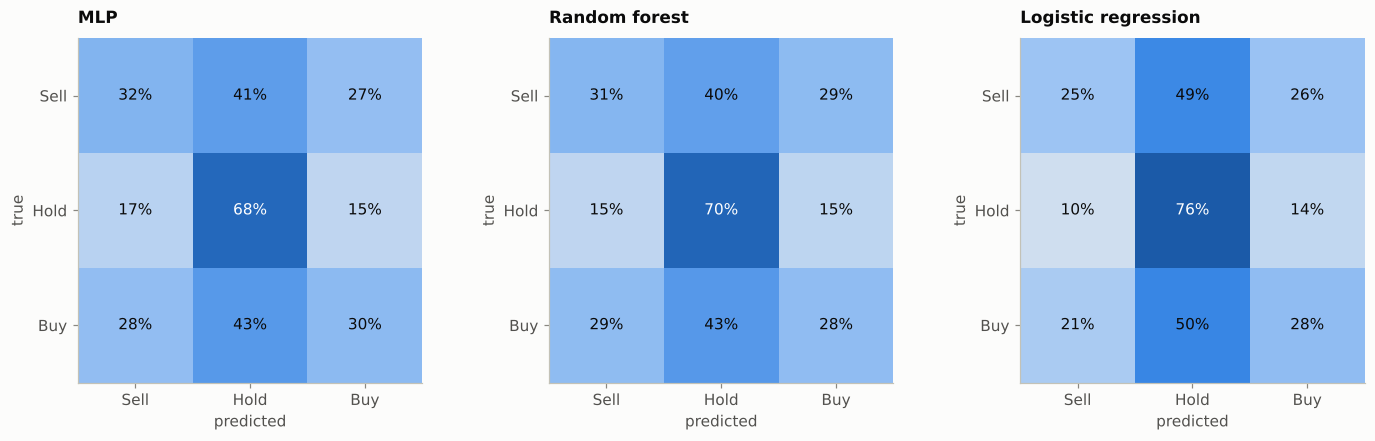

In [12]:
names = [CLASS_NAMES[c] for c in CLASS_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, m in zip(axes, shortlist):
    pred = val_proba[m]["pred"].reindex(y_val.index)
    cm = confusion_matrix(y_val, pred, labels=CLASS_ORDER, normalize="true")
    ax.imshow(cm, cmap=P.SEQUENTIAL, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.55 else P.INK)
    ax.set_xticks(range(3), names); ax.set_yticks(range(3), names)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False); ax.set_title(m, fontsize=11)
fig.tight_layout(); P.save(fig, "02_confusion_shortlist")

In [13]:
for m in shortlist:
    pred = val_proba[m]["pred"].reindex(y_val.index)
    print(f"\n{m}")
    print(classification_report(y_val, pred, labels=CLASS_ORDER, target_names=names, digits=3, zero_division=0))


MLP
              precision    recall  f1-score   support

        Sell      0.292     0.318     0.304       888
        Hold      0.554     0.679     0.610      1746
         Buy      0.447     0.296     0.356      1394

    accuracy                          0.466      4028
   macro avg      0.431     0.431     0.423      4028
weighted avg      0.459     0.466     0.455      4028


Random forest
              precision    recall  f1-score   support

        Sell      0.292     0.310     0.301       888
        Hold      0.560     0.695     0.621      1746
         Buy      0.430     0.284     0.342      1394

    accuracy                          0.468      4028
   macro avg      0.428     0.430     0.421      4028
weighted avg      0.456     0.468     0.454      4028


Logistic regression
              precision    recall  f1-score   support

        Sell      0.321     0.253     0.283       888
        Hold      0.539     0.758     0.630      1746
         Buy      0.454     0.283 

### Which features the models relied on

**Permutation importance:** shuffle one feature and measure how much macro-F1 drops. A bigger drop means the model relied on it more. For each shortlisted model, the model is refitted with its tuned settings for each of the last 4 validation years (2017–2020). Importance is measured on that year's predictions only, never on training rows, then averaged.

,MLP,Random forest,Logistic regression
ATR(14) / price,0.008,0.005,0.026
Return 5d,0.007,-0.001,0.000
Close / SMA20,0.007,-0.000,0.000
Historical volatility,0.004,0.004,0.000
Close / SMA50,0.003,-0.002,0.000
Return 10d,0.002,-0.002,0.000
RSI(14),0.000,-0.019,0.037
Return 1d,-0.001,-0.004,0.003
Return 20d,-0.003,0.002,0.000
MACD histogram / price,-0.003,-0.003,-0.010


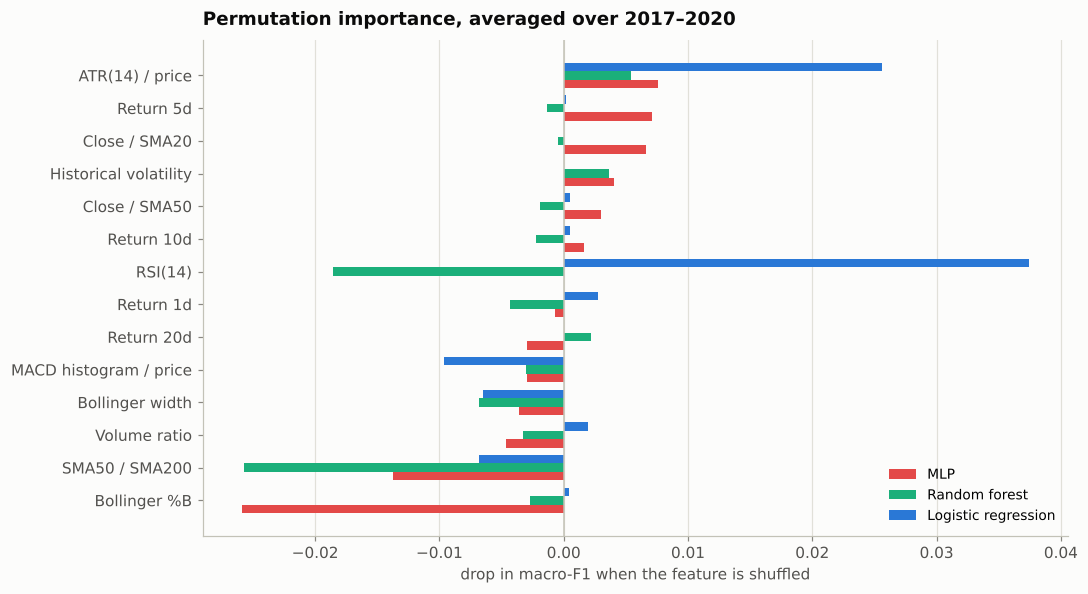

In [14]:
perm_rows = []
for m in shortlist:
    for f in [f for f in val_folds if f.year >= 2017]:
        params = val_log[(val_log.model == m) & (val_log.year == f.year)]["best_params"].iloc[0]
        est = make_search(m, len(f.train_idx)).estimator.set_params(**{f"model__{k}": (tuple(v) if isinstance(v, list) else v) for k, v in params.items()})
        est.fit(X.iloc[f.train_idx], y.iloc[f.train_idx])
        r = permutation_importance(est, X.iloc[f.test_idx], y.iloc[f.test_idx], scoring="f1_macro", n_repeats=10, random_state=0, n_jobs=1)
        perm_rows.append(pd.Series(r.importances_mean, index=FEATURES, name=(m, f.year)))
perm = pd.DataFrame(perm_rows)
perm_mean = perm.groupby(level=0).mean().T
perm_mean.index = [FEATURE_INFO[c][0] for c in perm_mean.index]
perm_mean = perm_mean[shortlist].sort_values(shortlist[0])
fig, ax = plt.subplots(figsize=(10, 5.5))
h = 0.26
for k, m in enumerate(shortlist):
    ax.barh(np.arange(len(perm_mean)) + (k - 1) * h, perm_mean[m], height=h, color=P.MODEL_COLORS[m], label=m)
ax.set_yticks(range(len(perm_mean)), perm_mean.index)
ax.axvline(0, color=P.AXIS, lw=1); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right"); ax.set_xlabel("drop in macro-F1 when the feature is shuffled")
ax.set_title("Permutation importance, averaged over 2017–2020")
fig.tight_layout(); P.save(fig, "02_permutation_importance")
perm_mean.sort_values(shortlist[0], ascending=False)

### Logistic regression coefficients

Logistic regression is the most readable model: each standardised feature gets one weight per class. A positive weight pushes towards that class. These are from the model fitted for 2020 (trained 1994–2019).

In [15]:
f_last = val_folds[-1]
params = val_log[(val_log.model == "Logistic regression") & (val_log.year == f_last.year)]["best_params"].iloc[0]
lr = make_search("Logistic regression", len(f_last.train_idx)).estimator.set_params(**{f"model__{k}": v for k, v in params.items()})
lr.fit(X.iloc[f_last.train_idx], y.iloc[f_last.train_idx])
coef = pd.DataFrame(lr[-1].coef_.T, index=[FEATURE_INFO[c][0] for c in FEATURES], columns=[CLASS_NAMES[c] for c in lr[-1].classes_])
coef.sort_values("Buy").style.background_gradient(cmap=P.DIVERGING, vmin=-coef.abs().max().max(), vmax=coef.abs().max().max()).format("{:+.3f}")

,Sell,Hold,Buy
Return 5d,+0.096,+0.000,-0.057
RSI(14),+0.000,+0.287,-0.003
Return 1d,+0.000,+0.000,-0.001
Return 10d,+0.000,+0.000,+0.000
Return 20d,+0.000,+0.000,+0.000
Close / SMA20,+0.000,+0.000,+0.000
Close / SMA50,+0.000,+0.000,+0.000
MACD histogram / price,-0.052,+0.000,+0.000
Volume ratio,+0.000,+0.000,+0.000
Bollinger %B,+0.000,+0.000,+0.000


### How each year's winning setting was chosen

The search ranks every candidate by its **mean** macro-F1 over the 5 practice years and keeps the top one; on an exact tie, the first one drawn wins. Below: the candidates for the 2020 fold of each shortlisted model, and how far the winner led the runner-up in every year. All candidates are saved in `results/tuning_candidates.json`; they were recorded by re-running the seeded searches, which reproduced all 150 yearly winners exactly.

In [16]:
CAND = json.load(open(RES / "tuning_candidates.json")) if (RES / "tuning_candidates.json").exists() else {}
if CAND:
    lead = pd.DataFrame({m: {int(y): c["candidates"][0]["mean"] - (c["candidates"][1]["mean"] if len(c["candidates"]) > 1 else np.nan)
                             for y, c in CAND[m].items() if int(y) <= 2020} for m in MODEL_NAMES if m != "Dummy"}).T
    print("Lead of the winner over the runner-up (macro-F1), per year:")
    display(lead.style.format("{:.4f}"))
    for m in shortlist:
        c = CAND[m]["2020"]
        t = pd.DataFrame([{"rank": r["rank"], "settings": r["params"], **dict(zip(c["inner_years"], r["folds"])), "mean": r["mean"], "sd": r["sd"]}
                          for r in c["candidates"]]).set_index("rank")
        print(); print(f"{m}: candidates for the 2020 fold (practice years {c['inner_years'][0]}-{c['inner_years'][-1]})")
        display(t.head(8))

Lead of the winner over the runner-up (macro-F1), per year:


,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
K-nearest neighbours,0.0010,0.0001,0.0043,0.0096,0.0074,0.0032,0.0029,0.0017,0.0036,0.0040,0.0004,0.0000,0.0000,0.0007,0.0007,0.0012
Logistic regression,0.0001,0.0001,0.0031,0.0074,0.0013,0.0051,0.0023,0.0031,0.0012,0.0015,0.0014,0.0014,0.0031,0.0012,0.0000,0.0000
Decision tree,0.0002,0.0013,0.0057,0.0104,0.0012,0.0012,0.0033,0.0019,0.0023,0.0027,0.0126,0.0027,0.0027,0.0087,0.0000,0.0066
Random forest,0.0013,0.0086,0.0019,0.0019,0.0001,0.0034,0.0042,0.0030,0.0024,0.0104,0.0230,0.0101,0.0069,0.0024,0.0029,0.0010
HistGradientBoosting,0.0037,0.0031,0.0016,0.0023,0.0007,0.0045,0.0033,0.0048,0.0052,0.0081,0.0128,0.0000,0.0074,0.0060,0.0033,0.0045
XGBoost,0.0012,0.0009,0.0016,0.0041,0.0018,0.0014,0.0029,0.0046,0.0053,0.0026,0.0011,0.0067,0.0018,0.0061,0.0086,0.0036
Perceptron,0.0145,0.0184,0.0057,0.0241,0.0108,0.0118,0.0055,0.0044,0.0099,0.0038,0.0021,0.0048,0.0034,0.0115,0.0146,0.0091
MLP,0.0003,0.0006,0.0028,0.0059,0.0013,0.0010,0.0043,0.0086,0.0048,0.0095,0.0076,0.0022,0.0030,0.0090,0.0017,0.0037



MLP: candidates for the 2020 fold (practice years 2015-2019)


,settings,2015,2016,2017,2018,2019,mean,sd
rank,,,,,,,,
1,"{'alpha': 0.000294, 'hidden_layer_sizes': [32, 16], 'learning_rate_init': 0.000829}",0.336,0.437,0.322,0.433,0.447,0.395,0.054
2,"{'alpha': 0.000351, 'hidden_layer_sizes': [16], 'learning_rate_init': 0.001718}",0.361,0.435,0.315,0.423,0.421,0.391,0.046
3,"{'alpha': 0.006647, 'hidden_layer_sizes': [16], 'learning_rate_init': 0.000796}",0.372,0.457,0.298,0.430,0.397,0.391,0.054
4,"{'alpha': 0.000748, 'hidden_layer_sizes': [32, 16], 'learning_rate_init': 0.000631}",0.352,0.424,0.323,0.430,0.422,0.390,0.044
5,"{'alpha': 0.006838, 'hidden_layer_sizes': [16], 'learning_rate_init': 0.000731}",0.359,0.450,0.304,0.418,0.417,0.390,0.052
6,"{'alpha': 0.000138, 'hidden_layer_sizes': [32, 16], 'learning_rate_init': 0.000817}",0.362,0.433,0.291,0.418,0.428,0.386,0.054
7,"{'alpha': 0.022674, 'hidden_layer_sizes': [32, 16], 'learning_rate_init': 0.000582}",0.345,0.381,0.333,0.443,0.418,0.384,0.042
8,"{'alpha': 0.081232, 'hidden_layer_sizes': [32], 'learning_rate_init': 0.000266}",0.353,0.444,0.284,0.387,0.398,0.373,0.053



Random forest: candidates for the 2020 fold (practice years 2015-2019)


,settings,2015,2016,2017,2018,2019,mean,sd
rank,,,,,,,,
1,"{'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 194, 'n_estimators': 200}",0.418,0.364,0.285,0.458,0.355,0.376,0.059
2,"{'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 119, 'n_estimators': 300}",0.393,0.382,0.285,0.416,0.400,0.375,0.046
3,"{'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 74, 'n_estimators': 100}",0.429,0.341,0.285,0.442,0.377,0.375,0.058
4,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 189, 'n_estimators': 300}",0.398,0.377,0.285,0.453,0.360,0.375,0.055
5,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 21, 'n_estimators': 200}",0.403,0.355,0.296,0.434,0.369,0.371,0.047
6,"{'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 94, 'n_estimators': 300}",0.396,0.369,0.285,0.459,0.339,0.370,0.058
7,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 70, 'n_estimators': 300}",0.415,0.350,0.285,0.421,0.365,0.367,0.050
8,"{'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 40, 'n_estimators': 100}",0.401,0.344,0.299,0.416,0.364,0.365,0.042



Logistic regression: candidates for the 2020 fold (practice years 2015-2019)


,settings,2015,2016,2017,2018,2019,mean,sd
rank,,,,,,,,
1,"{'C': 0.021619, 'l1_ratio': 1.0}",0.404,0.432,0.284,0.411,0.355,0.377,0.053
2,"{'C': 0.005417, 'l1_ratio': 1.0}",0.401,0.417,0.284,0.427,0.357,0.377,0.052
2,"{'C': 0.005415, 'l1_ratio': 1.0}",0.401,0.417,0.284,0.427,0.357,0.377,0.052
4,"{'C': 0.053429, 'l1_ratio': 0.0}",0.362,0.435,0.295,0.386,0.391,0.374,0.046
5,"{'C': 0.114009, 'l1_ratio': 1.0}",0.367,0.440,0.296,0.394,0.367,0.373,0.047
6,"{'C': 0.031489, 'l1_ratio': 0.0}",0.359,0.432,0.294,0.386,0.391,0.372,0.046
7,"{'C': 0.073629, 'l1_ratio': 0.0}",0.361,0.429,0.296,0.380,0.386,0.370,0.043
8,"{'C': 0.06072, 'l1_ratio': 0.0}",0.357,0.429,0.295,0.380,0.386,0.369,0.044


### Indicator importance for all 9 models, every validation year

The same permutation test, now for **every model** and **all 16 validation years**. It is also run on indicator **families** shuffled together (returns, trend, momentum, Bollinger, volatility, volume), so correlated indicators can't hide behind each other. Results are cached in `results/importance.json` (about 5 minutes to compute).

,Returns,Trend (moving averages),"Momentum (RSI, MACD)",Bollinger Bands,"Volatility (std, ATR)",Volume
MLP,+0.015,-0.006,+0.017,-0.015,+0.011,+0.000
Random forest,+0.008,-0.009,+0.005,+0.005,+0.020,+0.000
Logistic regression,+0.018,-0.004,+0.029,-0.012,+0.020,-0.001
K-nearest neighbours,+0.006,-0.002,+0.007,+0.003,+0.011,-0.006
Decision tree,+0.005,+0.003,-0.000,-0.015,+0.012,+0.000
XGBoost,-0.001,-0.006,+0.009,+0.002,+0.009,+0.002
HistGradientBoosting,+0.006,-0.004,+0.010,-0.007,+0.014,+0.000
Perceptron,+0.004,+0.014,+0.016,-0.005,+0.011,+0.003


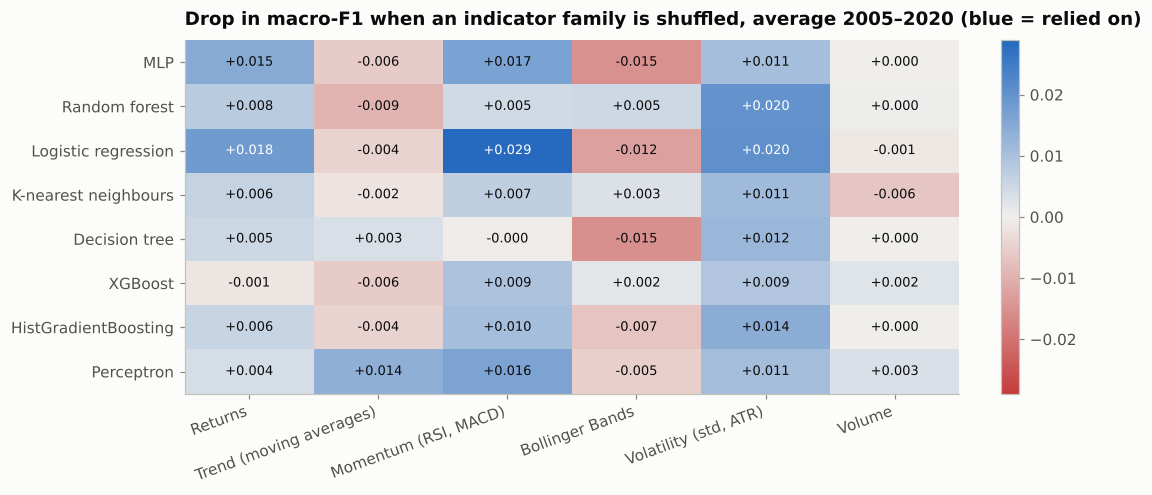

In [17]:
from src.importance import permutation_by_year, builtin_importance, GROUPS
imp_path = RES / "importance.json"
if imp_path.exists() and not QUICK:
    IMP = json.load(open(imp_path))
else:
    IMP = {}
    for m in MODEL_NAMES:
        s_, g_, est_ = permutation_by_year(m, X, y, val_folds, val_log)
        kind, bi = builtin_importance(m, est_)
        IMP[m] = {"single": s_.to_dict(orient="index"), "group": g_.to_dict(orient="index"), "builtin_kind": kind,
                  "builtin": None if bi is None else bi.to_dict(orient="index")}
    IMP["_corr"] = X.corr(method="spearman").to_dict(orient="index")
    json.dump(IMP, open(imp_path, "w"))
models_imp = [m for m in comparison.index if m in IMP and m != "Dummy"]
grp = pd.DataFrame({m: pd.DataFrame(IMP[m]["group"]).T.mean() for m in models_imp}).T
lim = np.abs(grp.values).max()
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(grp.values, cmap=P.DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(grp.shape[1]), grp.columns, rotation=20, ha="right"); ax.set_yticks(range(grp.shape[0]), grp.index)
for i in range(grp.shape[0]):
    for j in range(grp.shape[1]):
        ax.text(j, i, f"{grp.iat[i, j]:+.3f}", ha="center", va="center", fontsize=8.5, color="white" if abs(grp.iat[i, j]) > lim * 0.6 else P.INK)
ax.grid(False); ax.set_title("Drop in macro-F1 when an indicator family is shuffled, average 2005–2020 (blue = relied on)")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout(); P.save(fig, "02_group_importance_all_models")
grp.style.format("{:+.3f}")

## Modelling findings

1. **Every model beats the dummy; all but the perceptron (0.357) do so clearly.** The dummy scores 0.340 macro-F1. The top three, MLP (0.423), random forest (0.421) and logistic regression (0.421), are tied: their 95% intervals (about 0.40 to 0.44) overlap almost completely. Accuracy is 42–48% for the seven stronger models, against 35% for the dummy. That is above the brief's "35–40% is normal" because Hold is the largest class in 2005–2020 (43%) and the models lean towards it. It is far from the ~80% that would signal leakage, and the look-ahead tests pass.
2. **The skill is mostly in spotting calm weeks, not direction.** Hold recall is 0.68–0.76, while Buy and Sell recall are only 0.25–0.32. This matches the EDA: volatility tells you how big the next move will be, not which way.
3. **No model is reliable every year.** Yearly macro-F1 swings between about 0.25 and 0.46, and every model has years below the dummy (2005 and 2008 for most).
4. **Simple models did as well as complex ones.** L1-regularised logistic regression (L1 chosen in 13 of 16 years) matches the random forest and MLP, and beats XGBoost (0.399) and HistGradientBoosting (0.391). Extra flexibility found no extra signal.
5. **Unstable settings mean a flat landscape.** For the boosting models, no setting value won more than 5 of 16 years: many settings score about the same. Logistic regression, random forest (max_depth 8 in 11 years) and MLP (two layers, 32 and 16 neurons, in 14 years) were more stable.
6. **Feature effects are small; volatility and momentum matter most.** Averaged over all 16 years, every model relies on the volatility family (20-day volatility, ATR), and most rely on momentum (RSI, MACD). The trend family (moving-average ratios) slightly *hurts* 6 of the 8 models on new years. In 2017–2020, shuffling any single feature changes macro-F1 by at most about 0.04. Volatility (ATR) helps all three models, and logistic regression also leans on RSI. Several features have *negative* importance there: patterns learned from earlier years did not hold in those years. Correlated features also share credit, so single-feature importance understates groups.
7. **Shortlist for the money test:** MLP, random forest, logistic regression.